# 6장 part2 (6.1.5 ~)
## 6.1.5 ResNet
* forward() 먼저

In [127]:
def forward(self, x):
	i = x
	x = self.conv(x)
	x = self.bn1(x)
	x = self.relu(x)
	x = self.conv2d(x)
	x = self.bn2(x)

	if self.downsample is not None:
	  i = self.downsample(i) #다운샘플 적용

	x += I #아이덴티티 매핑 적용
	x = self.relu(x)
	return x

* 필요한 라이브러리 호출

In [128]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as data
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models

import matplotlib.pyplot as plt
import numpy as np

import copy
from collections import namedtuple #1
import os
import random
import time

import cv2
from torch.utils.data import DataLoader, Dataset
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

* (네임드튜플 예시)

In [129]:
from collections import namedtuple
Student = namedtuple('Student', ['name', 'age', 'DOB']) #네임드튜플 정의
S = Student('홍길동', '19', '187') #네임드튜플에 값 추가

print("The Student age using index is : ", end="")
print(S[1]) #인덱스 이용한 데이터 접근
print("The Student name using keyname is : ", end="")
print(S.name) #키 값 이용한 데이터 접근

The Student age using index is : 19
The Student name using keyname is : 홍길동


* 이미지 데이터 전처리

In [130]:
class ImageTransform():
  def __init__(self, resize, mean, std):
    self.data_transform = {
        'train': transforms.Compose([
            transforms.RandomResizedCrop(resize, scale=(0.5, 1.0)),
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ]), #훈련이미지 데이터에 대한 전처리
        'val': transforms.Compose([
            transforms.Resize(256),
            transforms.CenterCrop(resize),
            transforms.ToTensor(),
            transforms.Normalize(mean, std)
        ]) #검증과 테스트 이미지 데이터에 대한 전처리
    }

  def __call__(self, img, phase):
    return self.data_transform[phase](img)

* 변수에 대한 값 정의

In [131]:
size = 224
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
batch_size = 32

* (압축 해제)

In [132]:
import zipfile
import os

zip_path = 'chap06.zip'
extract_path = './'  # 현재 작업 디렉토리에 압축 해제

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("압축 해제가 완료되었습니다.")
else:
    print(f"'{zip_path}' 파일을 찾을 수 없습니다. 세션 저장소에 파일이 업로드되어 있는지 확인해 주세요.")

압축 해제가 완료되었습니다.


* 훈련과 테스트 데이터셋 불러오기

In [133]:
cat_directory = r'./chap06/data/dogs-vs-cats/Cat/'
dog_directory = r'./chap06/data/dogs-vs-cats/Dog/'

cat_images_filepaths = sorted([os.path.join(cat_directory, f) for f in os.listdir(cat_directory)])
dog_images_filepaths = sorted([os.path.join(dog_directory, f) for f in os.listdir(dog_directory)])
images_filepaths = [*cat_images_filepaths, *dog_images_filepaths]
correct_images_filepaths = [i for i in images_filepaths if cv2.imread(i) is not None]

* 데이터셋을 훈련, 검증, 테스트 용도로 분리

In [134]:
random.seed(42)
random.shuffle(correct_images_filepaths)
train_images_filepaths = correct_images_filepaths[:400]
val_images_filepaths = correct_images_filepaths[400:-10]
test_images_filepaths = correct_images_filepaths[-10:]
print(len(train_images_filepaths), len(val_images_filepaths),
      len(test_images_filepaths))

400 92 10


* 이미지에 대한 레이블 구분

In [135]:
class DogvsCatDataset(Dataset):
  def __init__(self, file_list, transform=None, phase='train'):
    self.file_list = file_list
    self.transform = transform
    self.phase = phase

  def __len__(self):
    return len(self.file_list)

  def __getitem__(self, idx):
    img_path = self.file_list[idx]
    img = Image.open(img_path)
    img_transformed = self.transform(img, self.phase)

    label = img_path.split('/')[-1].split('.')[0]
    if label == 'dog':
      label = 1
    elif label == 'cat':
      label = 0
    return img_transformed, label

* 이미지 데이터셋 정의

In [136]:
train_dataset = DogvsCatDataset(train_images_filepaths,
                                transform=ImageTransform(size, mean, std), phase='train')
val_dataset = DogvsCatDataset(val_images_filepaths,
                              transform=ImageTransform(size, mean, std), phase='val')
index = 0
print(train_dataset.__getitem__(index)[0].size())
print(train_dataset.__getitem__(index)[1])

torch.Size([3, 224, 224])
0


* 데이터셋의 데이터를 메모리로 불러오기

In [137]:
train_iterator = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_iterator = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
dataloader_dic = {'train': train_iterator, 'val': valid_iterator}
batch_iterator = iter(train_iterator)
inputs, label = next(batch_iterator)
print(inputs.size())
print(label)

torch.Size([32, 3, 224, 224])
tensor([1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0,
        0, 1, 1, 1, 0, 0, 0, 0])


* 기본 블록 정의

In [138]:
class BasicBlock(nn.Module):
  expansion = 1

  def __init__(self, in_channels, out_channels, stride=1, downsample=False):
    super().__init__()
    self.cov1 = nn.Conv2d(in_channels, out_channels, kernel_size=3,
                          stride=stride, padding=1, bias=False) # 3x3 합성곱층
    self.bn1 = nn.BatchNorm2d(out_channels)
    self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                           stride=1, padding=1, bias=False) #3x3 합성곱층
    self.bn2 = nn.BatchNorm2d(out_channels)
    self.relu = nn.ReLU(inplace=True)

    if downsample:
      conv = nn.Conv2d(in_channels, out_channels, kernel_size=1,
                       stride=stride, bias=False)
      bn = nn.BatchNorm2d(out_channels)
      downsample = nn.Sequential(conv, bn)
    else:
      downsample = None
    self.downsample = downsample

  def forward(self, x):
    i = x
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.conv2(x)
    x = self.bn2(x)

    if self.downsample is not None:
      i = self.downsample(i)

    x += i
    x = self.relu(x)

    return x

* (아이덴티티 매핑 예시)

In [139]:
def forward(self, x):
  i = x
  x = self.conv1(x)
  x = self.bn1(x)
  x = self.relu(x)
  x = self.conv2(x)
  x = self.bn2(x)
  x = self.relu(x)
  x = self.conv3(x)
  x = self.bn3(x)

  if self.downsample is not None:
    i = self.downsample(i)

  x += i
  x = self.relu(x)

  return x

* 병목 블록 정의

In [140]:
class Bottleneck(nn.Module):
  expansion = 4 #병목블록 정의 위한 하이퍼파라미터

  def __init__(self, in_channels, out_channels, stride=1, downsample=False):
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=1,
                           stride=1, bias=False) #1x1 합성곱층
    self.bn1 = nn.BatchNorm2d(out_channels)
    self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3,
                           stride=stride, padding=1, bias=False) #3x3 합성곱층
    self.bn2 = nn.BatchNorm2d(out_channels)
    self.conv3 = nn.Conv2d(out_channels, self.expansion*out_channels,
                           kernel_size=1, stride=1, bias=False) #1x1 합성곱층
    self.bn3 = nn.BatchNorm2d(self.expansion*out_channels)
    self.relu = nn.ReLU(inplace=True)

    if downsample:
      conv = nn.Conv2d(in_channels, self.expansion*out_channels, kernel_size=1,
                       stride=stride, bias=False)
      bn = nn.BatchNorm2d(self.expansion*out_channels)
      downsample = nn.Sequential(conv, bn)
    else:
      downsample = None
    self.downsample = downsample

  def forward(self, x):
    i = x
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.conv2(x)
    x = self.bn2(x)
    x = self.relu(x)
    x = self.conv3(x)
    x = self.bn3(x)

    if self.downsample is not None:
      i = self.downsample(i)

    x += i
    x = self.relu(x)

    return x


* ResNet 모델 네트워크

In [141]:
class ResNet(nn.Module):
  def __init__(self, config, output_dim, zero_init_residual=False):
    super().__init__()
    block, n_blocks, channels = config
    self.in_channels = channels[0]
    assert len(n_blocks) == len(channels) == 4
    self.conv1 = nn.Conv2d(3, self.in_channels, kernel_size=7, stride=2,
                           padding=3, bias=False)
    self.bn1 = nn.BatchNorm2d(self.in_channels)
    self.relu = nn.ReLU(inplace=True)
    self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)

    self.layer1 = self.get_resnet_layer(block, n_blocks[0], channels[0])
    self.layer2 = self.get_resnet_layer(block, n_blocks[1], channels[1], stride=2)
    self.layer3 = self.get_resnet_layer(block, n_blocks[2], channels[2], stride=2)
    self.layer4 = self.get_resnet_layer(block, n_blocks[3], channels[3], stride=2)

    self.avgpool = nn.AdaptiveAvgPool2d((1,1))
    self.fc = nn.Linear(self.in_channels, output_dim)

    if zero_init_residual:
      for m in self.modules():
        if isinstance(m, Bottelneck):
          nn.init.constant_(m.bn3.weight, 0)
        elif isinstance(m, BasicBlock):
          nn.init.constant_(m.bn2.weight, 0)

  def get_resnet_layer(self, block, n_blocks, channels, stride=1):
    layers = []
    if self.in_channels != block.expansion * channels:
      downsample = True
    else:
      downsample = False

    layers.append(block(self.in_channels, channels, stride, downsample))
    for i in range(1, n_blocks):
      layers.append(block(block.expansion*channels, channels))

    self.in_channels = block.expansion * channels
    return nn.Sequential(*layers)

  def forward(self, x):
    x = self.conv1(x)
    x = self.bn1(x)
    x = self.relu(x)
    x = self.maxpool(x)
    x = self.layer1(x)
    x = self.layer2(x)
    x = self.layer3(x)
    x = self.layer4(x)
    x = self.avgpool(x)
    h = x.view(x.shape[0], -1)
    x = self.fc(h)
    return x, h

* ResNetConfig 정의

In [142]:
ResNetConfig = namedtuple('ResNetConfig', ['block', 'n_blocks', 'channels'])

* 기본 블록을 사용하여 ResNetConfig 정의

In [143]:
resnet18_config = ResNetConfig(block=BasicBlock,
                               n_blocks=[2,2,2,2],
                               channels=[64,128,256,512])

resnet34_config = ResNetConfig(block=BasicBlock,
                               n_blocks=[3,4,6,3],
                               channels=[64,128,256,512])

* 병목 블록 사용하여 ResNetConfig 정의

In [144]:
resnet50_config = ResNetConfig(block=Bottleneck,
                               n_blocks=[3,4,6,3],
                               channels=[64,128,256,512])

resnet101_config = ResNetConfig(block=Bottleneck,
                                n_blocks=[3,4,23,3],
                                channels=[64,128,256,512])

resnet152_config = ResNetConfig(block=Bottleneck,
                                n_blocks=[3,8,36,3],
                                channels=[64,128,256,512])

* 사전 훈련된 ResNet 모델 사용

In [145]:
pretrained_model = models.resnet50(pretrained=True)

* 사전 훈련된 ResNet 네트워크 확인

In [146]:
print(pretrained_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [147]:
OUTPUT_DIM = 2
model = ResNet(resnet50_config, OUTPUT_DIM)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

* 옵티마이저와 손실함수 정의

In [148]:
optimizer = optim.Adam(model.parameters(), lr=1e-7)
criterion = nn.CrossEntropyLoss()
model = model.to(device)
criterion = criterion.to(device)

* 모델 학습 정확도 측정 함수 정의

In [149]:
def calculate_topk_accuracy(y_pred, y, k=2):
    with torch.no_grad():
        batch_size = y.shape[0]
        _, top_pred = y_pred.topk(k, 1)
        top_pred = top_pred.t()
        correct = top_pred.eq(y.view(1, -1).expand_as(top_pred))
        correct_1 = correct[:1].reshape(-1).float().sum(0, keepdim=True)
        correct_k = correct[:k].reshape(-1).float().sum(0, keepdim=True)
        acc_1 = correct_1 / batch_size
        acc_k = correct_k / batch_size
    return acc_1, acc_k

* (tensor.topk 예시)

In [150]:
import torch
x = torch.arange(1., 6.)
print(x)
print('----------')
print(torch.topk(x, 3))

tensor([1., 2., 3., 4., 5.])
----------
torch.return_types.topk(
values=tensor([5., 4., 3.]),
indices=tensor([4, 3, 2]))


* (t() 예시)

In [151]:
x = torch.rand(3)
print(x)
print(torch.t(x))
print('---------')
x = torch.randn(3, 2)
print(x)
print(torch.t(x))

tensor([0.3924, 0.2843, 0.4428])
tensor([0.3924, 0.2843, 0.4428])
---------
tensor([[-0.9203, -0.7405],
        [ 0.2837,  0.5034],
        [-1.2713, -0.6575]])
tensor([[-0.9203,  0.2837, -1.2713],
        [-0.7405,  0.5034, -0.6575]])


* (torch.eq 예시)

In [152]:
torch.eq(torch.tensor([[1, 2], [3, 4]]), torch.tensor([[1, 1], [4, 4]]))

tensor([[ True, False],
        [False,  True]])

* 모델 학습 함수 정의

In [153]:
def train(model, iterator, optimizer, criterion, scheduler, device):
    epoch_loss = 0
    epoch_acc_1 = 0
    epoch_acc_5 = 0

    model.train()
    for (x, y) in iterator:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        y_pred = model(x)
        loss = criterion(y_pred[0], y)

        acc_1, acc_5 = calculate_topk_accuracy(y_pred[0], y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc_1 += acc_1.item()
        epoch_acc_5 += acc_5.item()

    epoch_loss /= len(iterator)
    epoch_acc_1 /= len(iterator)
    epoch_acc_5 /= len(iterator)
    return epoch_loss, epoch_acc_1, epoch_acc_5

* 모델 평가 함수 정의

In [154]:
def evaluate(model, iterator, criterion, device):
    epoch_loss = 0
    epoch_acc_1 = 0
    epoch_acc_5 = 0

    model.eval()
    with torch.no_grad():
        for (x, y) in iterator:
            x = x.to(device)
            y = y.to(device)
            y_pred = model(x)
            loss = criterion(y_pred[0], y)

            acc_1, acc_5 = calculate_topk_accuracy(y_pred[0], y)
            epoch_loss += loss.item()
            epoch_acc_1 += acc_1.item()
            epoch_acc_5 += acc_5.item()

    epoch_loss /= len(iterator)
    epoch_acc_1 /= len(iterator)
    epoch_acc_5 /= len(iterator)
    return epoch_loss, epoch_acc_1, epoch_acc_5

* 모델 학습 시간 측정 함수 정의

In [155]:
def epoch_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

* 모델 학습

In [157]:
best_valid_loss = float('inf')
EPOCHS = 10

scheduler = None

for epoch in range(EPOCHS):
    start_time = time.monotonic()

    train_loss, train_acc_1, train_acc_5 = train(model, train_iterator, optimizer, criterion, scheduler, device)
    valid_loss, valid_acc_1, valid_acc_5 = evaluate(model, valid_iterator, criterion, device)

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), './chap06/data/ResNet-model.pt')

    end_time = time.monotonic()
    epoch_mins, epoch_secs = epoch_time(start_time, end_time)

    print(f'Epoch: {epoch+1:02} | Epoch Time: {epoch_mins}m {epoch_secs}s')
    print(f'\tTrain Loss: {train_loss:.3f} | Train Acc @1: {train_acc_1*100:.2f}% | Train Acc @5: {train_acc_5*100:.2f}%')
    print(f'\tValid Loss: {valid_loss:.3f} | Valid Acc @1: {valid_acc_1*100:.2f}% | Valid Acc @5: {valid_acc_5*100:.2f}%')

Epoch: 01 | Epoch Time: 0m 6s
	Train Loss: 0.702 | Train Acc @1: 49.52% | Train Acc @5: 100.00%
	Valid Loss: 0.697 | Valid Acc @1: 48.81% | Valid Acc @5: 100.00%
Epoch: 02 | Epoch Time: 0m 7s
	Train Loss: 0.700 | Train Acc @1: 49.76% | Train Acc @5: 100.00%
	Valid Loss: 0.698 | Valid Acc @1: 47.77% | Valid Acc @5: 100.00%
Epoch: 03 | Epoch Time: 0m 6s
	Train Loss: 0.692 | Train Acc @1: 51.44% | Train Acc @5: 100.00%
	Valid Loss: 0.686 | Valid Acc @1: 58.78% | Valid Acc @5: 100.00%
Epoch: 04 | Epoch Time: 0m 6s
	Train Loss: 0.698 | Train Acc @1: 49.28% | Train Acc @5: 100.00%
	Valid Loss: 0.691 | Valid Acc @1: 54.76% | Valid Acc @5: 100.00%
Epoch: 05 | Epoch Time: 0m 7s
	Train Loss: 0.689 | Train Acc @1: 52.64% | Train Acc @5: 100.00%
	Valid Loss: 0.686 | Valid Acc @1: 51.19% | Valid Acc @5: 100.00%
Epoch: 06 | Epoch Time: 0m 6s
	Train Loss: 0.695 | Train Acc @1: 50.96% | Train Acc @5: 100.00%
	Valid Loss: 0.689 | Valid Acc @1: 52.23% | Valid Acc @5: 100.00%
Epoch: 07 | Epoch Time: 0m 7

* 테스트 데이터셋을 이용한 모델 예측

In [160]:
import pandas as pd
id_list = []
pred_list = []
_id = 0
with torch.no_grad():
    for test_path in test_images_filepaths:
        img = Image.open(test_path)
        _id = test_path.split('/')[-1].split('.')[1]
        transform = ImageTransform(size, mean, std)
        img = transform(img, phase='val')
        img = img.unsqueeze(0)
        img = img.to(device)

        model.eval()
        outputs = model(img)
        preds = F.softmax(outputs[0], dim=1)[:, 1].tolist()
        id_list.append(_id)
        pred_list.append(preds[0])

res = pd.DataFrame({
    'id': id_list,
    'label': pred_list
})

res.sort_values(by='id', inplace=True)
res.reset_index(drop=True, inplace=True)

res.to_csv('./chap06/data/ResNet.csv', index=False)
res.head(10)

,id,label
0,109,0.631571
1,145,0.620124
2,15,0.599507
3,162,0.551198
4,167,0.510797
5,200,0.624055
6,210,0.591528
7,211,0.578030
8,213,0.496708
9,224,0.587175


* 모델 예측에 대한 결과 출력

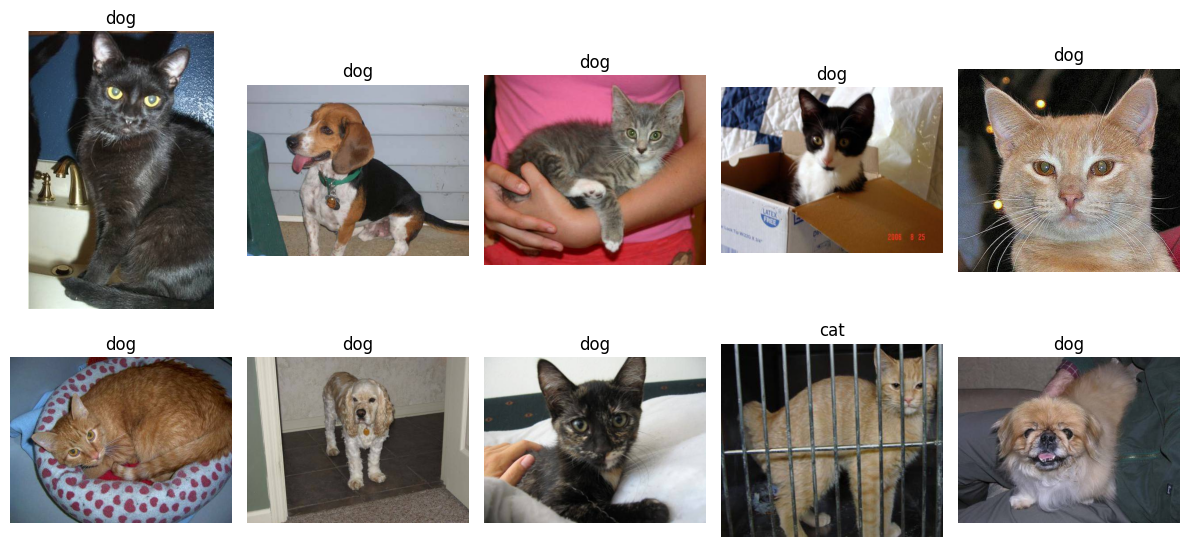

In [161]:
class_ = classes = {0:'cat', 1:'dog'}
def display_image_grid(images_filepaths, predicted_labels=(), cols=5):
    rows = len(images_filepaths) // cols
    figure, ax = plt.subplots(nrows=rows, ncols=cols, figsize=(12, 6))
    for i, image_filepath in enumerate(images_filepaths):
        image = cv2.imread(image_filepath)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        a = random.choice(res['id'].values)
        label = res.loc[res['id'] == a, 'label'].values[0]

        if label > 0.5:
            label = 1
        else:
            label = 0
        ax.ravel()[i].imshow(image)
        ax.ravel()[i].set_title(class_[label])
        ax.ravel()[i].set_axis_off()
    plt.tight_layout()
    plt.show()
display_image_grid(test_images_filepaths)